**NUR-E-JANNAT ANIKA**

CS 251/2: Data Analysis and Visualization

Fall 2025

Project 4: Clustering

In [17]:
import numpy as np
import matplotlib.pyplot as plt

import kmeans

plt.style.use(['seaborn-v0_8-colorblind', 'seaborn-v0_8-darkgrid'])
plt.rcParams.update({'font.size': 20})

np.set_printoptions(suppress=True, precision=5)


# Automatically reload external modules
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Task 2: Image Segmentation and quantization

In this task, you will apply K-means to one image and to quantize it (*this is a version of the image with fewer colors, and fewer colors allows image formats to compress the images*). The idea is that you will find $k$ RGB color centroids in the image, then replace each pixel in the image with the nearest centroid. The resulting picture  will use only $k$ colors to represent it. You can also think of this as doing a simple image region segmentation: regions with similar colors will belong to the same cluster. It also makes some cool retro effects!

### 2a. Load in frog image

1. Use the imported `imread` method below to load in the `frog.jpg` image.
2. Use `plt.imshow` to display it in the notebook below. Turn off plot ticks!

In [18]:
from matplotlib.image import imread                    
  

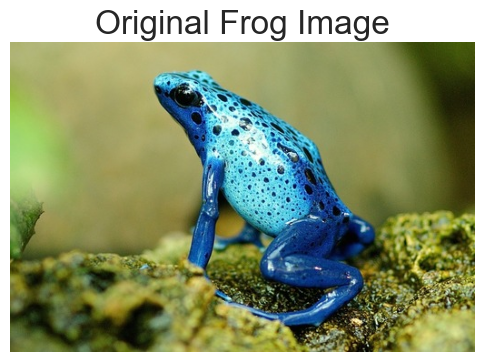

In [19]:
# YOUR CODE HERE                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    
frog_img = imread("data/frog.jpg")                    

# Display the image
plt.figure(figsize=(6, 6))
plt.imshow(frog_img)
plt.title("Original Frog Image")
plt.axis("off")  
plt.show()

### 2b. Preprocess image

In the two cells below:
1. Fill in the function below to collapse (flatten) the 2D image into a big 1D vector of RGB values. For example, for the frog image, your function should take the shape `(num_rows, num_cols, rgb)` and convert it to `(num_rows*num_cols, rgb)`.
2. Reshape the frog image from `(num_rows, num_cols, rgb)` and convert it to `(num_rows*num_cols, rgb)`.

In [20]:
def flatten(img):
    '''Flattens `img` to N 1D vectors.
    For example, for an RGB image, `(num_rows, num_cols, rgb)` -> `(num_rows*num_cols, rgb)`.

    Parameters:
    -----------
    img: ndarray. shape=(num_rows, num_cols, rgb)

    Returns:
    -----------
    Flattened `img`. ndarray. shape=(num_rows*num_cols, rgb)
    '''
    num_rows, num_cols, rgb = img.shape                    
  
    flat_img = img.reshape(num_rows * num_cols, rgb)

    return flat_img

In [21]:
frog_flat = flatten(frog_img)
print("Original shape:", frog_img.shape)

Original shape: (341, 512, 3)


#### Test frog image shape

In [22]:
print(f'The shape of your frog image after flattening is\n{frog_flat.shape}')
print('and it should be\n(174592, 3)')

The shape of your frog image after flattening is
(174592, 3)
and it should be
(174592, 3)


### 2c. Cluster RGB values in image

1. Run K-means on the flattened frog image. Cluster the image so that the quantized/clustered image will have only 3 colors.
2. Implement `replace_color_with_centroid`: replace every pixel in the image with the nearest centroid RGB value.
3. Quantize the image by running `replace_color_with_centroid`.

In [29]:
# YOUR CODE HERE                                                            
k = 3  
frog_kmeans = kmeans.KMeans(k=k, max_iters=50)

frog_kmeans.set_data(frog_flat)
np.random.seed(0)
frog_kmeans.cluster()                                       
  
print("Centroid colors (RGB):")
print(frog_kmeans.centroids)

Centroid colors (RGB):
[[117 132  86]
 [111 126  85]
 [116 131  84]]


In [30]:
def replace_color_with_centroid(img_flat, labels, centroids):
    """
    Replace every pixel's RGB value with its cluster centroid's RGB value.

    Parameters
    ----------
    img_flat : ndarray, shape=(num_pixels, 3)
        Flattened image array.
    labels : ndarray, shape=(num_pixels,)
        Cluster label for each pixel.
    centroids : ndarray, shape=(k, 3)
        Centroid RGB values from K-Means.

    Returns
    -------
    quantized_flat : ndarray, shape=(num_pixels, 3)
        Quantized flattened image.                    
    """
    quantized_flat = centroids[labels]  
    return quantized_flat


In [31]:
quantized_flat = replace_color_with_centroid(
    frog_flat,
    frog_kmeans.labels,
    frog_kmeans.centroids
)
quantized_frog = quantized_flat.reshape(frog_img.shape)

### 2d. Postprocessing and visualization

Reshape the quantized image data back to its original dimensions and cast the ndarray so that it stores ints.

Plot the quantized image below.

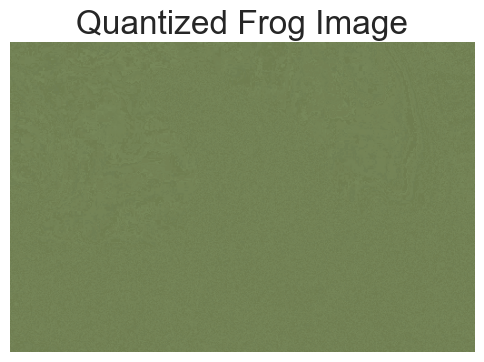

In [48]:
quantized_frog = quantized_frog.astype('uint8')                    
plt.figure(figsize = (6, 6))
plt.imshow(quantized_frog)
plt.title("Quantized Frog Image")
plt.axis("off")                      
plt.show()


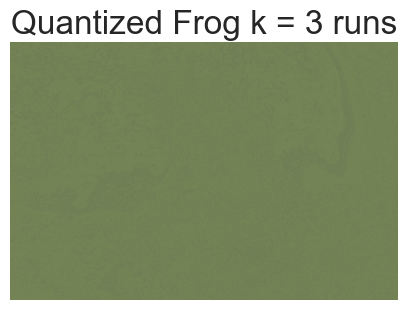

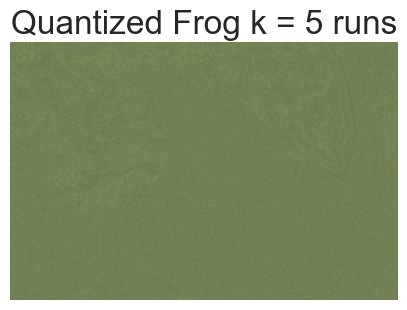

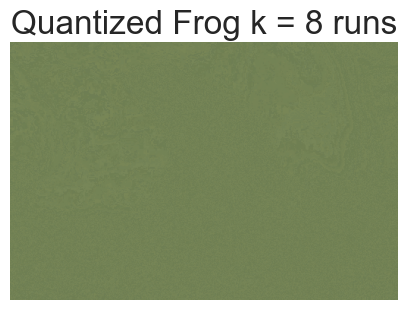

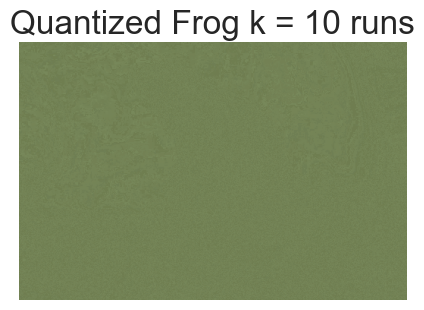

In [51]:
for k in [3, 5, 8, 10]:
    frog_kmeans = kmeans.KMeans(k = k, max_iters = 50)
    frog_kmeans.set_data(frog_flat)
    np.random.seed(0)
    frog_kmeans.cluster()
    quantized_flat = frog_kmeans.centroids[frog_kmeans.labels]
    quantized_frog = quantized_flat.reshape(frog_img.shape).astype('uint8')
    plt.figure(figsize = (5,5))
    plt.imshow(quantized_frog)
    plt.axis("off")
    plt.title(f"Quantized Frog k = {k} runs")                    
    plt.show()


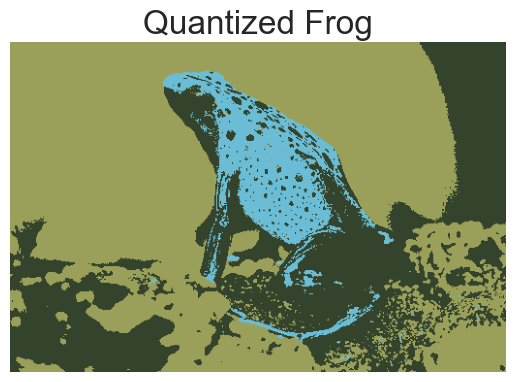

In [52]:
'''I was constantly getting quatized image like the abover one where nothing is shown, I couldn't understand why and 
then I had to ask chapgpt and it suggested to normalize. So I tried with normalizing and it seemeed to work.'''

flat_frog = frog_img.reshape(-1, 3) / 255.0   
frog_kmeans = kmeans.KMeans(k = 3, max_iters = 50)
frog_kmeans.set_data(flat_frog)
np.random.seed(15)
frog_kmeans.cluster()

quantized_flat = frog_kmeans.centroids[frog_kmeans.labels]
quantized_frog = (quantized_flat.reshape(frog_img.shape) * 255).astype('uint8')

plt.imshow(quantized_frog)
plt.axis("off")
plt.title("Quantized Frog")
plt.show()


### 2e. Run K-means and quantize an image of your choice

Smaller images run a lot faster.

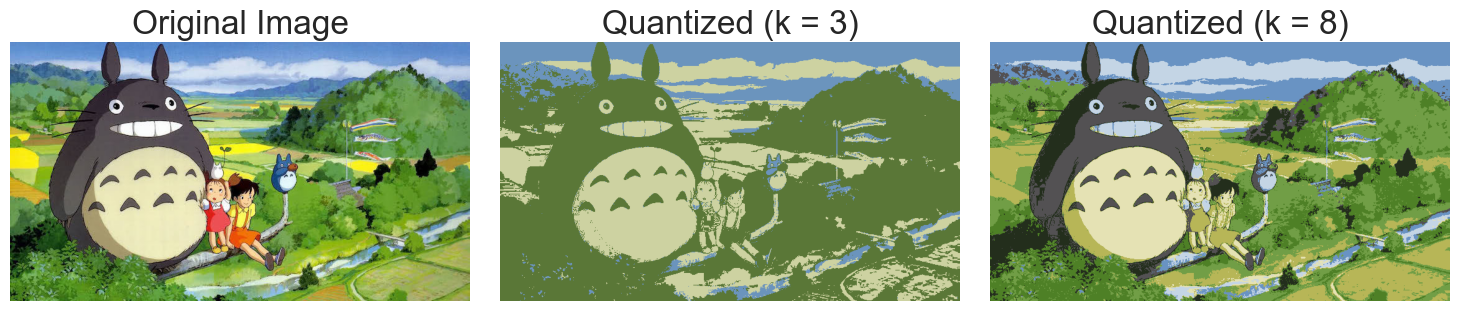

In [54]:
my_img = imread("data/Totoro.jpg")                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     
flat_img = my_img.reshape(-1, 3)
if flat_img.dtype != np.float64:
    flat_img = flat_img / 255.0   

def quantize_image(flat_img, shape, k):
    model = kmeans.KMeans(k = k, max_iters = 50)
    model.set_data(flat_img)
    np.random.seed(0)
    model.cluster()
    quantized_flat = model.centroids[model.labels]
    return (quantized_flat.reshape(shape) * 255).astype(np.uint8)
    
quantized_k3 = quantize_image(flat_img, my_img.shape, 3)
quantized_k8 = quantize_image(flat_img, my_img.shape, 8)
                    

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(my_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(quantized_k3)
axes[1].set_title(f"Quantized (k = 3)")
axes[1].axis("off")

axes[2].imshow(quantized_k8)
axes[2].set_title(f"Quantized (k = 8)")
axes[2].axis("off")

plt.tight_layout()
plt.show()                   
                                          
                

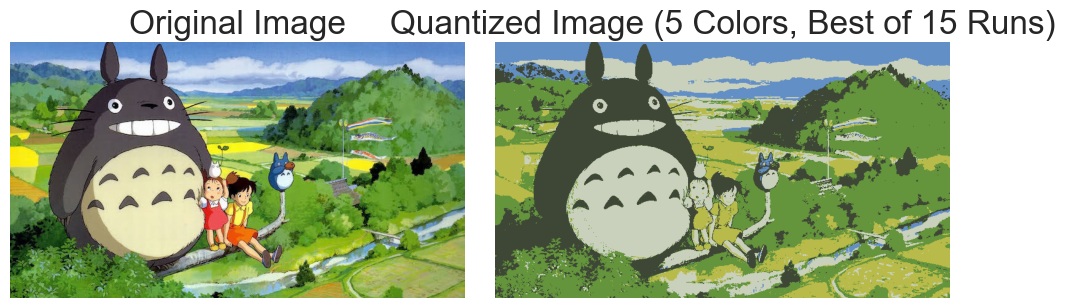

In [55]:
# Or with batch_clustering
img_kmeans = kmeans.KMeans(max_iters = 100)
img_kmeans.set_data(flat_img)
np.random.seed(0)
img_kmeans.cluster_batch(k = 5, n_iter = 15)  

quantized_flat = img_kmeans.centroids[img_kmeans.labels]
quantized_img = (quantized_flat.reshape(my_img.shape) * 255).clip(0,255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize = (10, 5))
axes[0].imshow(my_img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(quantized_img)
axes[1].set_title("Quantized Image (5 Colors, Best of 15 Runs)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

